# Circle (CRCL) valuation with stochastic interest rates and USDC supply

Question: how much is Circle worth when revenue depends on stochastic rates and USDC supply, and which rate path does today's share price imply?

## 0. Setup

In [280]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
import requests
from scipy import stats, optimize
import statsmodels.api as sm

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)

START_RATES = "2000-01-01"
START_CRCL = "2025-06-01"
END_DATE = "2026-10-17"  # data cutoff: all series are cut here so results do not change with each run
CIK_CIRCLE = "0001876042"

## 1. Data collection
### 1.1 CRCL price (yfinance)

[*********************100%***********************]  1 of 1 completed


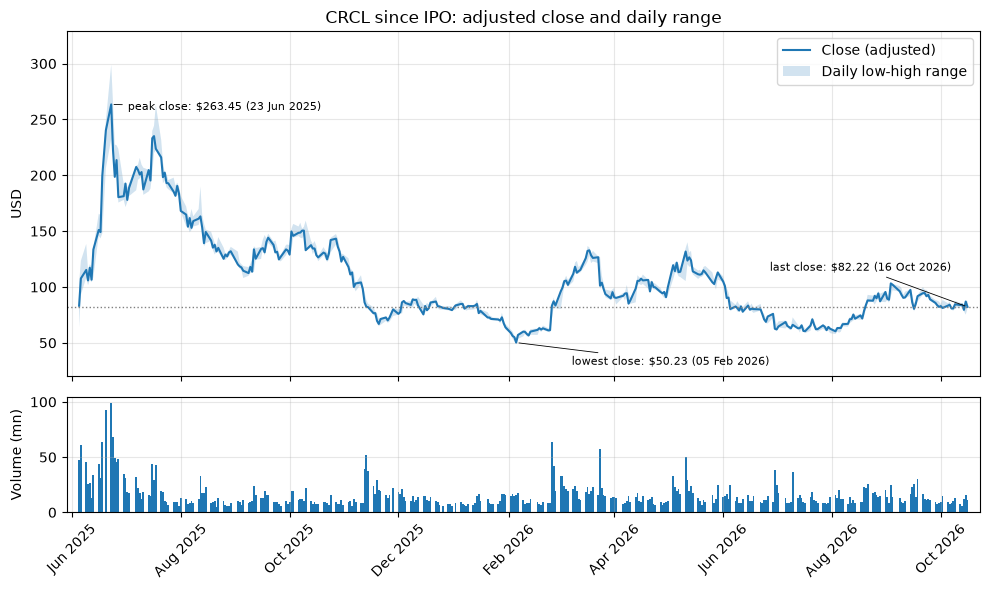

In [281]:
crcl = yf.download("CRCL", start=START_CRCL, auto_adjust=True)
crcl.columns = crcl.columns.droplevel("Ticker")
crcl.columns.name = None
crcl = crcl.loc[:END_DATE]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(crcl.index, crcl["Close"], lw=1.5, label="Close (adjusted)")
ax1.fill_between(crcl.index, crcl["Low"], crcl["High"], alpha=0.2, label="Daily low-high range")
marks = {  # label: (date, text offset in points, horizontal alignment)
    "peak close": (crcl["Close"].idxmax(), (12, -4), "left"),
    "lowest close": (crcl["Close"].idxmin(), (40, -16), "left"),
    "last close": (crcl.index[-1], (-12, 26), "right"),
}
for name, (d, offset, ha) in marks.items():
    ax1.annotate(f"{name}: ${crcl.loc[d, 'Close']:.2f} ({d:%d %b %Y})", xy=(d, crcl.loc[d, "Close"]),
                 xytext=offset, textcoords="offset points", ha=ha, fontsize=8,
                 arrowprops=dict(arrowstyle="-", lw=0.6))
ax1.axhline(crcl["Close"].iloc[-1], ls=":", lw=1, color="gray")  # today's price as reference
ax1.margins(y=0.12)
ax1.set_ylabel("USD")
ax1.set_title("CRCL since IPO: adjusted close and daily range")
ax1.legend(loc="upper right")
ax2.bar(crcl.index, crcl["Volume"] / 1e6, width=1.0)
ax2.set_ylabel("Volume (mn)")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[2, 4, 6, 8, 10, 12]))  # fixed even months, independent of the data limits
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.tick_params(axis="x", labelrotation=45)
ax2.set_xlim(crcl.index[0] - pd.Timedelta(days=7), crcl.index[-1] + pd.Timedelta(days=7))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation (CRCL).** CRCL went public on 5 Jun 2025 (open $69.00, close $83.23), reached its highest close of $263.45 on 23 Jun 2025 (intraday high $298.99) and its lowest close of $50.23 on 5 Feb 2026. The last close is $82.22 on 16 Oct 2026: 69% below the peak and about the same as the IPO-day close (-1.2%). Volume peaked during the run-up (99 mn shares on 23 Jun 2025) and is now about 11 mn shares a day (20-day mean), against a median of 12 mn. The price the model will be compared with is therefore the one after a large fall from the peak, not the IPO price.

### 1.2 3-month T-bill (FRED DTB3)
Daily series DTB3 from FRED, starting in 2000 so the sample includes several rate regimes. It is the proxy for the reserve return that the rate model will simulate.

,tbill_3m
observation_date,
2026-10-09,4.06
2026-10-13,4.09
2026-10-14,4.10
2026-10-15,4.10
2026-10-16,4.08


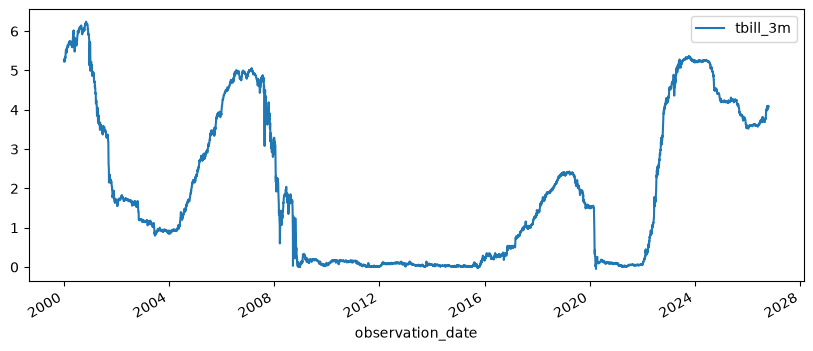

In [282]:
tbill = pd.read_csv(
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3",
    index_col=0, parse_dates=True, na_values=".",
).rename(columns={"DTB3": "tbill_3m"})
tbill = tbill.loc[START_RATES:END_DATE].dropna()
tbill.plot();
tbill.tail()

**Interpretation (T-bill):** The 3-month T-bill rate is 4.08% on 16 Oct 2026. Since 2000 it has moved between very different regimes: annual averages of 5.82% in 2000, 1.01% in 2003, 4.73% in 2006 and 5.07% in 2023. It stayed below 0.25% from March 2009 to December 2015 and from April 2020 to February 2022, about a third of the sample, with a low of -0.05% in March 2020. Reserve income depends on short-term rates: the quarterly average of the T-bill (4.23, 4.10, 3.73, 3.59 and 3.62%) stays within 0.13 pp of the reserve return rate that Circle reports (4.1, 4.2, 3.8, 3.5 and 3.5%), so the T-bill is a reasonable driver for the rate model. Limitation: a Vasicek model allows negative rates and has a single long-run mean, while this sample mixes near-zero and 5% regimes, so the calibrated mean will depend on the window chosen.

### 1.3 USDC supply (DefiLlama, id 2)
Daily circulating USDC supply in USD, full history since 2018. Steps: download, build the DataFrame, check quarter-end values.

In [283]:
url = "https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=2"
raw = requests.get(url, timeout=30)
raw.raise_for_status()
usdc_raw = raw.json()
print(len(usdc_raw))
usdc_raw[0], usdc_raw[-1]

2970


({'date': '1536624000',
  'totalCirculating': {'peggedUSD': 2},
  'totalCirculatingUSD': {'peggedUSD': 2}},
 {'date': '1793145600',
  'totalCirculating': {'peggedUSD': 71330416686.79},
  'totalUnreleased': {'peggedUSD': 1061675523.45},
  'totalCirculatingUSD': {'peggedUSD': 71298534608.51},
  'totalMintedUSD': {'peggedUSD': 0},
  'totalBridgedToUSD': {'peggedUSD': 0}})

,usdc_supply
date,
2026-10-13,"72,860,344,009.00"
2026-10-14,"73,133,116,485.00"
2026-10-15,"72,763,096,585.00"
2026-10-16,"72,828,793,768.00"
2026-10-17,"72,734,876,026.00"


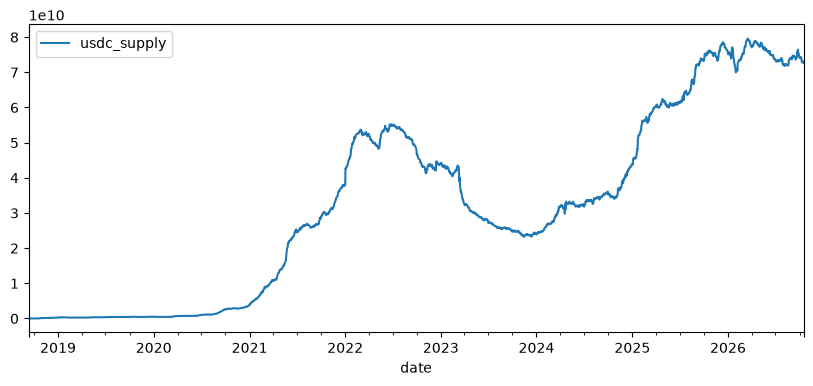

In [284]:
usdc = pd.DataFrame(
    {
        "date": pd.to_datetime([int(x["date"]) for x in usdc_raw], unit="s"),
        "usdc_supply": [x["totalCirculatingUSD"]["peggedUSD"] for x in usdc_raw],
    }
).set_index("date")
usdc = usdc.loc[:END_DATE]
usdc.plot();
usdc.tail()

In [285]:
# Quarter-end USDC supply, $ bn. The last row is partial: data is cut at END_DATE (2026-10-17), it is not a quarter end.
(usdc["usdc_supply"].resample("QE").last() / 1e9).round(1).loc["2021":]

date
2021-03-31   10.90
2021-06-30   24.60
2021-09-30   28.70
2021-12-31   38.10
2022-03-31   52.50
2022-06-30   54.90
2022-09-30   47.90
2022-12-31   44.10
2023-03-31   32.60
2023-06-30   27.70
2023-09-30   24.70
2023-12-31   24.00
2024-03-31   31.90
2024-06-30   31.90
2024-09-30   36.00
2024-12-31   43.80
2025-03-31   60.30
2025-06-30   61.30
2025-09-30   73.20
2025-12-31   76.00
2026-03-31   77.40
2026-06-30   73.70
2026-09-30   74.60
2026-12-31   72.70
Freq: QE-DEC, Name: usdc_supply, dtype: float64

**Interpretation (USDC):** USDC supply peaked at $55.2bn on 20 Jun 2022, fell to $23.2bn on 15 Nov 2023 (-58%), reached a high of $79.6bn on 18 Mar 2026 and stands at $72.7bn on 17 Oct 2026. The fall began in mid-2022 and was sharpest around March 2023: supply went from $43.2bn on 8 Mar to $38.0bn on 15 Mar, the week of the SVB failure. Since the start of 2026 it has moved between $70.0bn and $79.6bn. The series has three regimes (growth, decline, recovery) followed by a plateau, so a single growth rate depends on the calibration window.

**SVB / regime decision:** which window calibrates USDC growth is decided in section 3, and the result under other windows is shown as a sensitivity.

### 1.4 Circle quarterly figures (releases, 10-Q/10-K, S-1)
Every hand-entered number cites its source in a comment.

In [286]:
# Circle quarterly figures, $ billions (USDC) and $ millions (income). Q2 2025 to Q2 2026.
# Sources (8-K exhibit 99.1, earnings releases):
#  Q2 2025: sec.gov/Archives/edgar/data/1876042/000162828025039749/q22025epr.htm
#  Q3 2025: sec.gov 8-K 0001876042-25-000045 (release of 2025-11-12; table read from the Business Wire copy)
#  Q4 2025: sec.gov/Archives/edgar/data/1876042/000187604226000032/final_circlereportsfourt.htm
#  Q1 2026: sec.gov/Archives/edgar/data/0001876042/000187604226000148/final_05x11q1epr30.htm
#  Q2 2026: sec.gov/Archives/edgar/data/1876042/000187604226000246/augustepr-circle_q22026f.htm
circle_q = pd.DataFrame(
    {
        "avg_usdc_bn":       [61.0, 67.8, 76.2, 75.2, 76.5],   # Key Operating Indicators
        "end_usdc_bn":       [61.3, 73.7, 75.3, 77.0, 73.3],   # Key Operating Indicators
        "reserve_return_pct":[4.1,  4.2,  3.8,  3.5,  3.5],    # Key Operating Indicators
        "reserve_income":    [634,  711,  733,  653,  668],    # Quarterly Results of Operations
        "total_revenue":     [658,  740,  770,  694,  701],    # idem
        "dist_trans_costs":  [406,  447,  461,  405,  410],    # distribution and transaction costs
        "total_costs":       [407,  448,  461,  407,  412],    # distribution, transaction and other costs
        "rldc":              [251,  292,  309,  287,  289],    # revenue less distribution costs
    },
    index=pd.PeriodIndex(["2025Q2", "2025Q3", "2025Q4", "2026Q1", "2026Q2"], freq="Q"),
)
circle_q

,avg_usdc_bn,end_usdc_bn,reserve_return_pct,reserve_income,total_revenue,dist_trans_costs,total_costs,rldc
2025Q2,61.00,61.30,4.10,634,658,406,407,251
2025Q3,67.80,73.70,4.20,711,740,447,448,292
2025Q4,76.20,75.30,3.80,733,770,461,461,309
2026Q1,75.20,77.00,3.50,653,694,405,407,287
2026Q2,76.50,73.30,3.50,668,701,410,412,289


In [287]:
# Consistency checks on the hand-entered table
assert ((circle_q["total_revenue"] - circle_q["total_costs"] - circle_q["rldc"]).abs() <= 1).all()  # RLDC = revenue - costs (rounding tolerance 1)
implied = circle_q["avg_usdc_bn"] * 1e3 * circle_q["reserve_return_pct"] / 100 / 4  # avg USDC x reserve return / 4, $ mn
(implied - circle_q["reserve_income"]).round(0)

2025Q2   -9.00
2025Q3    1.00
2025Q4   -9.00
2026Q1    5.00
2026Q2    1.00
Freq: Q-DEC, dtype: float64

**Interpretation (Circle table):** The table has five quarters (Q2 2025 to Q2 2026) taken from Circle's earnings releases (8-K). Reserve income is explained by average USDC times the reserve return rate: the implied figure is within $9mn of the reported one in every quarter (under 1.5%), consistent with the return rate being rounded to one decimal. Distribution and transaction costs are 61% to 64% of reserve income (61.4% in Q2 2026), and the RLDC margin is 38% to 41% of total revenue. Average USDC grew from $61.0bn to $76.5bn while the reserve return rate fell from 4.1% to 3.5%, and reserve income stayed between $634mn and $733mn. These two moves happened in the same period, but five points cannot show a relationship between them. Limitation: five quarters allow calibrating margins and the cost share, not estimating a statistical pattern, and the sample covers only a period of falling rates.

### 1.5 Save raw data

In [288]:
crcl.to_csv("../data/crcl_prices.csv")
tbill.to_csv("../data/tbill_3m.csv")
usdc.to_csv("../data/usdc_supply.csv")
circle_q.to_csv("../data/circle_quarterly.csv")

## 2. Unit economics
Goal: reduce Circle's quarterly results to per-dollar-of-USDC quantities, which are what the model will project later.

Definitions used below (all from the table in 1.4, quarterly figures in $ mn unless noted):
- **Reserve income**: interest earned on the reserves backing USDC.
- **Distribution and transaction costs**: mostly payments to partners such as Coinbase.
- **RLDC** (revenue less distribution and transaction costs): the profit measure Circle reports before operating expenses.
- **RLDC yield**: annualised RLDC divided by average USDC. It is the profit Circle earns per year for each dollar of USDC in circulation.

### 2.1 Reserve income identity
Check that reserve income is explained by average USDC times the reserve return.

In [289]:
uq = circle_q.copy()
uq["implied_return_pct"] = uq["reserve_income"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised reserve income / avg USDC
uq[["implied_return_pct", "reserve_return_pct"]]

,implied_return_pct,reserve_return_pct
2025Q2,4.16,4.10
2025Q3,4.19,4.20
2025Q4,3.85,3.80
2026Q1,3.47,3.50
2026Q2,3.49,3.50


**Interpretation (reserve income).** The implied return is within 0.06 pp of the reported one in all five quarters, and the gap is consistent with Circle reporting the return rounded to one decimal. Reserve income is therefore average USDC times the reserve return, so the model needs only these two variables.

### 2.2 Cost structure
How much of reserve income is passed on to partners, how much revenue is not reserve income, and the resulting RLDC margin.

In [290]:
uq["dist_share"] = uq["dist_trans_costs"] / uq["reserve_income"]  # distribution and transaction costs / reserve income
uq["other_revenue"] = uq["total_revenue"] - uq["reserve_income"]  # revenue that is not reserve income, $ mn
uq["rldc_margin"] = uq["rldc"] / uq["total_revenue"]
uq[["dist_share", "other_revenue", "rldc_margin"]]

,dist_share,other_revenue,rldc_margin
2025Q2,0.64,24,0.38
2025Q3,0.63,29,0.39
2025Q4,0.63,37,0.40
2026Q1,0.62,41,0.41
2026Q2,0.61,33,0.41


**Interpretation (cost structure).** Distribution and transaction costs are 61% to 64% of reserve income (61% in 2026Q2, falling slowly), so Circle keeps about 39 cents of each dollar of reserve income. Non-reserve revenue is $24 mn to $41 mn per quarter, 3.6% to 5.9% of total revenue, and total costs exceed distribution costs by only $0 to $2 mn, so that revenue reaches RLDC almost in full. The RLDC margin on total revenue is stable at 38% to 41%. If the partner share stays constant, a $100 mn fall in reserve income lowers RLDC by about $38 mn; this assumption is tested in the sensitivity section.

### 2.3 RLDC yield
Profit per dollar of USDC, compared with the reserve return.

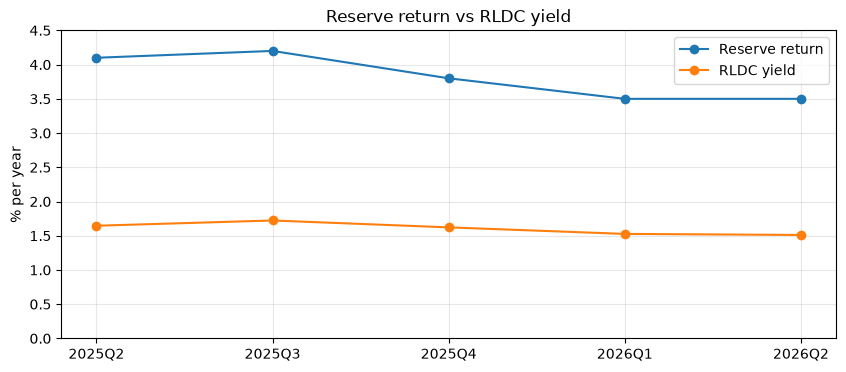

,reserve_return_pct,rldc_yield_pct
2025Q2,4.10,1.65
2025Q3,4.20,1.72
2025Q4,3.80,1.62
2026Q1,3.50,1.53
2026Q2,3.50,1.51


In [291]:
uq["rldc_yield_pct"] = uq["rldc"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised RLDC per $ of average USDC

fig, ax = plt.subplots()
x = uq.index.astype(str)
ax.plot(x, uq["reserve_return_pct"], marker="o", label="Reserve return")
ax.plot(x, uq["rldc_yield_pct"], marker="o", label="RLDC yield")
ax.set_ylim(0, 4.5)
ax.set_ylabel("% per year")
ax.set_title("Reserve return vs RLDC yield")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

uq[["reserve_return_pct", "rldc_yield_pct"]]

**Interpretation (RLDC yield).**
- RLDC yield fell from 1.65% (2025Q2) to 1.51% (2026Q2), about 8.5%, while the reserve return fell from 4.10% to 3.50%, about 15%. The yield fell less than rates because the distribution share of reserve income dropped from 64% to 61% and non-reserve revenue grew from $24 mn to $33 mn per quarter.
- From the 2025Q3 peak (1.72% at a 4.20% return) to 2026Q2, each 1 pp drop in the reserve return cost about 0.3 pp of yield. With five quarters and non-reserve revenue growing at the same time, this is an observation, not a calibrated parameter. It is tested in the sensitivity section.

### 2.4 Operating expenses
RLDC is before operating expenses. This block adds them to get operating income and the yield that is left per dollar of USDC.

In [292]:
# Operating expenses, $ mn. Source: Circle Q2 2026 earnings release, 8-K exhibit 99.1 (five-quarter table):
# https://www.sec.gov/Archives/edgar/data/1876042/000187604226000246/augustepr-circle_q22026f.htm
# 2025Q2 includes about $435 mn of one-off stock compensation from the IPO.
uq["opex"] = [576.7, 211.1, 253.6, 242.4, 254.5]
uq["operating_income"] = uq["rldc"] - uq["opex"]
uq["opex_yield_pct"] = uq["opex"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised opex per $ of average USDC
uq["operating_yield_pct"] = uq["rldc_yield_pct"] - uq["opex_yield_pct"]
uq[["rldc", "opex", "operating_income", "rldc_yield_pct", "opex_yield_pct", "operating_yield_pct"]]

,rldc,opex,operating_income,rldc_yield_pct,opex_yield_pct,operating_yield_pct
2025Q2,251,576.70,-325.70,1.65,3.78,-2.14
2025Q3,292,211.10,80.90,1.72,1.25,0.48
2025Q4,309,253.60,55.40,1.62,1.33,0.29
2026Q1,287,242.40,44.60,1.53,1.29,0.24
2026Q2,289,254.50,34.50,1.51,1.33,0.18


**Interpretation (operating expenses).**
- 2025Q2 is not comparable: its opex includes about $435 mn of one-off stock compensation from the IPO, which produces an operating yield of -2.14%. It is excluded from any average or calibration.

- From 2025Q3 to 2026Q2, operating income fell from $81 mn to $35 mn per quarter. RLDC stayed between $287 mn and $309 mn while opex rose from $211 mn to $255 mn (about 20%).

- Per dollar of USDC, the operating yield fell from 0.48% to 0.18%. RLDC yield fell from 1.72% to 1.51% and opex yield rose from 1.25% to 1.33%.

- The profit left after operating costs is a small difference between two large numbers (1.51% minus 1.33%), so the valuation is very sensitive to the opex assumption. Opex growth relative to USDC growth becomes a key assumption of the DCF and is tested in the sensitivity section.

- Opex includes $52 mn to $59 mn per quarter of stock-based compensation, a non-cash cost that dilutes shareholders. The DCF keeps it as a cost.

## 3. Calibration (Vasicek via AR(1), GBM for USDC)

### 3.1 Vasicek calibration (AR(1) on the 3-month T-bill)
Regress each month-end rate on the previous month-end rate and convert the coefficients into the Vasicek parameters. Month-end (point-in-time) values are used because monthly averages smooth the series and understate volatility. First pass on the full sample; other choices come next.

In [293]:
# Month-end T-bill rate, in % (point-in-time values; the last month, Oct 2026, is partial and is dropped)
rate_m = tbill["tbill_3m"].resample("ME").last().iloc[:-1]
dt = 1 / 12  # time between observations, in years

def fit_vasicek(r, dt):
    """AR(1): r[t+1] = a + b * r[t] + error. Returns the Vasicek parameters."""
    x, y = r.values[:-1], r.values[1:]
    b, a = np.polyfit(x, y, 1)                # slope and intercept of the regression
    s = (y - (a + b * x)).std(ddof=2)         # std of the regression residual
    kappa = -np.log(b) / dt                   # speed of mean reversion, per year
    theta = a / (1 - b)                       # long-run mean, in %
    sigma = s * np.sqrt(2 * kappa / (1 - b**2))  # volatility, in % per sqrt(year)
    return {"a": a, "b": b, "kappa": kappa, "theta": theta, "sigma": sigma, "half_life_years": np.log(2) / kappa}

pd.Series(fit_vasicek(rate_m, dt))

a                 0.01
b                 0.99
kappa             0.11
theta             1.44
sigma             0.72
half_life_years   6.07
dtype: float64

**Interpretation (historical fit).** The full-sample AR(1) on month-end rates gives b = 0.991, kappa = 0.11, theta = 1.44% and sigma = 0.72, with a half-life of 6.1 years. Theta is below every rate regime in the sample: it averages the near-zero periods (about a third of the sample) with the 4-5% periods. Used as a base case, it would assume a large fall in rates by construction of the window. It is kept as the stress case. With monthly averages instead of month-end values, sigma would be 0.65: averaging smooths the series.

### 3.2 Vasicek parameters: base case and stress case
Base case: theta = Fed median longer-run rate (3.2%, September 2026 projections); kappa fitted so the model reproduces the Fed's median path for 2026-2029; sigma from the historical fit in 3.1. Stress case: the full-sample historical fit from 3.1.

In [294]:
hist = fit_vasicek(rate_m, dt)  # historical fit from 3.1 (full sample)
r0 = tbill["tbill_3m"].iloc[-1]  # last T-bill observation, %
THETA_BASE = 3.2  # Fed longer-run median, September 2026 projections
# Fed median fed funds rate by year end, September 2026 projections:
# https://federalreserve.gov/monetarypolicy/fomcprojtabl20260916.htm
fed = pd.Series({2026: 4.1, 2027: 4.1, 2028: 3.9, 2029: 3.6})
t_fed = (fed.index + 1 - 2026.8).values  # years from late Oct 2026 to each year end

def path(kappa, theta, t):
    """Expected Vasicek rate at time t: theta + (r0 - theta) * exp(-kappa * t)."""
    return theta + (r0 - theta) * np.exp(-kappa * t)

loss = lambda k: ((path(k, THETA_BASE, t_fed) - fed.values) ** 2).sum()
kappa_base = optimize.minimize_scalar(loss, bounds=(0.01, 3), method="bounded").x

params = {
    "base":   {"kappa": kappa_base,    "theta": THETA_BASE,    "sigma": hist["sigma"]},
    "stress": {"kappa": hist["kappa"], "theta": hist["theta"], "sigma": hist["sigma"]},
}
pd.DataFrame(params).T

,kappa,theta,sigma
base,0.15,3.20,0.72
stress,0.11,1.44,0.72


**Interpretation (base and stress parameters).** Base case: theta = 3.2% (Fed median longer-run rate, September 2026 projections; participants range from 2.9% to 3.9%), kappa = 0.15 fitted to the Fed median path, sigma = 0.72 from history. The fitted path (4.05, 3.93, 3.83, 3.74%) is within 0.17 pp of the Fed medians (4.1, 4.1, 3.9, 3.6%). Expected rate in 1, 5 and 10 years: 3.96%, 3.61%, 3.39% (base) and 3.79%, 2.93%, 2.28% (stress). Limitation: the Fed projects the federal funds rate, not the T-bill (4.1% vs 4.08% today), and its projections are committee medians, not market forecasts.

### 3.3 GBM for USDC: growth and volatility by window
Month-end USDC supply and monthly log returns. For a GBM, the mean of the log return is mu - sigma^2/2 (Ito correction), so mu = mean log return + sigma^2/2. Monthly data are used because daily data hide the persistence of USDC flows and contain isolated jumps that look like counting errors (for example -6.8%, +8.4% and +7.0% between 18 and 22 April 2024).

In [295]:
usdc_bn = usdc["usdc_supply"] / 1e9
usdc_m = usdc_bn.resample("ME").last().iloc[:-1]  # month-end supply, $ bn (partial Oct 2026 dropped)
logret = np.log(usdc_m).diff().dropna()            # monthly log returns

def fit_gbm(lr, per_year=12):
    """GBM from monthly log returns: sigma = std * sqrt(12); mu = mean * 12 + sigma^2 / 2 (Ito)."""
    sigma = lr.std() * np.sqrt(per_year)
    mean_log = lr.mean() * per_year
    return {"months": len(lr), "mean_log_growth_pct": mean_log * 100, "mu_pct": (mean_log + sigma**2 / 2) * 100, "sigma_pct": sigma * 100}

windows = {  # months of the returns; each return runs from the previous month end
    "since 2021-01": ("2021-01", None),
    "peak to trough (Jun 2022 to Nov 2023)": ("2022-07", "2023-11"),
    "since trough (Nov 2023)": ("2023-12", None),
    "since 2024-01": ("2024-01", None),
    "since 2025-01": ("2025-01", None),
    "last 12 months": ("2025-10", None),
}
print(f"Autocorrelation of monthly returns since 2021: {logret.loc['2021-01':].autocorr():.2f}")
pd.DataFrame({k: fit_gbm(logret.loc[a:b]) for k, (a, b) in windows.items()}).T

Autocorrelation of monthly returns since 2021: 0.64


,months,mean_log_growth_pct,mu_pct,sigma_pct
since 2021-01,69.00,52.19,60.66,41.15
peak to trough (Jun 2022 to Nov 2023),17.00,-59.00,-56.68,21.51
since trough (Nov 2023),34.00,40.33,42.27,19.71
since 2024-01,33.00,41.20,43.19,19.96
since 2025-01,21.00,30.40,32.36,19.78
last 12 months,12.00,1.86,2.76,13.38


**Interpretation (USDC by window).** Expected growth (mu) ranges from -57% to +61% a year depending on the window, and volatility from 13% to 41%. Expected growth (mu) was 42% a year from the November 2023 trough (about 50% a year compounded), but USDC was flat over the last 12 months (mu +2.8%). Monthly returns are persistent (autocorrelation 0.64 since 2021): once USDC starts growing or shrinking, it tends to continue for months. A GBM assumes independent shocks and does not capture this; the growth scenarios in 3.4 cover changes of regime, and sigma covers fluctuations within each scenario. With daily data, sigma since 2021 would be 17% instead of 41%, because daily returns hide this persistence. No window can be used alone as a 10-year forecast.

### 3.4 USDC volatility, correlation and growth scenarios
Sigma of USDC from month-end returns since 2022 (excludes 2021, when USDC grew from $3.7bn to $38bn; includes the 2022-23 decline and the recovery). Correlation between monthly rate changes and monthly USDC log returns since 2022 (same window as sigma). Growth scenarios are anchored on external sources or observed data until 2030 and then fade to long-run nominal growth. All parameters are stored in decimals in `calib`.

In [296]:
pd.set_option("display.max_colwidth", None)  # show full text in table cells

shocks = pd.DataFrame({"d_rate": rate_m.diff(), "usdc_logret": logret}).loc["2022-01":].dropna()  # same window as sigma
rho, p_value = stats.pearsonr(shocks["d_rate"], shocks["usdc_logret"])
sigma_usdc = fit_gbm(logret.loc["2022-01":])["sigma_pct"] / 100  # month-end returns since 2022
print(f"rho = {rho:.2f}, p-value = {p_value:.3f}, months = {len(shocks)}")
print(f"sigma USDC = {sigma_usdc:.3f} (monthly returns since 2022-01)")

# USDC growth scenarios. The drift changes with time:
# stage 1 (now to end 2030): scenario growth; stage 2 (2031 to year 10): linear fade to long-run growth.
S0 = usdc_bn.iloc[-1]  # USDC supply at END_DATE, $ bn
T1 = 2031 - 2026.8     # years from late Oct 2026 to end 2030
HORIZON = 10           # projection horizon, years
G_LONG = 0.04          # long-run nominal growth: Fed longer-run real GDP 2.0% + PCE inflation 2.0% (Sep 2026 projections)
STABLE_NOW, STABLE_2030 = 309, 2000  # stablecoin supply now and 2030 forecast, $ bn (Standard Chartered, 14 Oct 2026)
mu1 = {
    "bear": 0.0,                                    # flat: last-12-month growth is -3.6% to +2.8% depending on the end dates
    "base": np.log(1.4),                            # Circle 40% through-cycle CAGR target
    "bull": np.log(STABLE_2030 / STABLE_NOW) / T1,  # market reaches $2tn, USDC keeps its share
}

def mu_t(t, m1):
    """Drift at time t (years): m1 until T1, then linear fade to log(1 + G_LONG) at HORIZON."""
    m_long = np.log(1 + G_LONG)
    w = np.clip((t - T1) / (HORIZON - T1), 0, 1)
    return m1 + (m_long - m1) * w

def expected_usdc(t, m1, n=2001):
    """E[S_t] = S0 * exp(integral of mu from 0 to t), integral by the trapezoid rule."""
    s = np.linspace(0, t, n)
    m = mu_t(s, m1)
    return S0 * np.exp(((m[1:] + m[:-1]) / 2 * np.diff(s)).sum())

# Everything the simulation needs, in decimals (rates converted from %)
calib = {
    "r0": r0 / 100,
    "rates": {k: {"kappa": v["kappa"], "theta": v["theta"] / 100, "sigma": v["sigma"] / 100} for k, v in params.items()},
    "S0": S0, "T1": T1, "HORIZON": HORIZON, "G_LONG": G_LONG,
    "mu1": mu1, "sigma_usdc": sigma_usdc, "rho": rho,
}

sources = {
    "bear": "Flat: observed growth over the last 12 months",
    "base": "Circle 40% CAGR target",
    "bull": "Standard Chartered $2tn market, constant USDC share",
}
scenarios = pd.DataFrame({
    "Source": sources,
    "mu to 2030 (continuous)": mu1,
    "Annual growth to 2030 (%)": {k: (np.exp(m) - 1) * 100 for k, m in mu1.items()},
    "USDC 2030 ($ bn)": {k: expected_usdc(T1, m) for k, m in mu1.items()},
    "Share of $2tn market (%)": {k: expected_usdc(T1, m) / STABLE_2030 * 100 for k, m in mu1.items()},
    "USDC year 10, mean ($ bn)": {k: expected_usdc(HORIZON, m) for k, m in mu1.items()},
    "USDC year 10, median ($ bn)": {k: expected_usdc(HORIZON, m) * np.exp(-sigma_usdc**2 * HORIZON / 2) for k, m in mu1.items()},
}).loc[["bear", "base", "bull"]]
scenarios

rho = -0.27, p-value = 0.046, months = 57
sigma USDC = 0.266 (monthly returns since 2022-01)


,Source,mu to 2030 (continuous),Annual growth to 2030 (%),USDC 2030 ($ bn),Share of $2tn market (%),"USDC year 10, mean ($ bn)","USDC year 10, median ($ bn)"
bear,Flat: observed growth over the last 12 months,0.00,0.00,72.73,3.64,81.50,57.15
base,Circle 40% CAGR target,0.34,40.00,298.87,14.94,888.48,623.09
bull,"Standard Chartered $2tn market, constant USDC share",0.44,56.00,470.78,23.54,"1,915.30","1,343.20"


**Interpretation (calibration summary).**
- Growth until end 2030: bear 0% (flat: growth over the last 12 months was -3.6% measured from 17 Oct to 17 Oct and +2.8% measured from end of September to end of September; USDC stays at $73bn); base 40% a year, Circle's through-cycle CAGR target ($299bn in 2030, 15% of Standard Chartered's $2tn stablecoin market, so USDC loses share to competitors); bull 56% a year (the market reaches $2tn and USDC keeps its 23.5% share: $471bn in 2030). The Standard Chartered forecast is read as end of 2030, and Circle's multi-year target (no end date given) is applied until end 2030.

- From 2031, growth fades linearly to 4% a year in year 10 (Fed longer-run real GDP 2.0% plus PCE inflation 2.0%, September 2026 projections). Expected (mean) USDC in year 10: $82bn (bear), $888bn (base) and $1.9tn (bull). With sigma of 27%, the median is about 30% lower ($57bn, $623bn and $1.3tn): a few very high paths pull the mean up, so the mean is not the typical outcome.

- Both external anchors lean optimistic: Standard Chartered already moved its $2tn forecast from 2028 to 2030 after supply stalled at $300-320bn, and the 40% target is set by Circle's management. The bear case uses observed data for that reason.

- Sigma of USDC = 27% a year, from month-end returns since 2022.

- Rho = -0.27 (p = 0.046, 57 months since 2022): higher rates coincide with lower USDC supply, as in 2022. Across windows (since 2021 or 2022) and methods (rate changes or AR(1) residuals), rho stays between -0.24 and -0.30, always with a p-value below 0.05. This is a partial natural hedge: when rates fall, the yield per dollar falls but USDC tends to grow.

- Circle's 2026 guidance for other revenue ($310-330 mn) includes ARC token presale revenue, which looks non-recurring. It is treated separately in the DCF.

## 4. Monte Carlo and DCF

### 4.1 Simulation of rate and USDC paths
10,000 correlated paths over 10 years in monthly steps. Both models use their exact solutions, so each step has no discretisation error: Vasicek for the short rate and GBM with time-varying drift for USDC (Ito). The two Brownian shocks are correlated by Cholesky with the rho from 3.4.

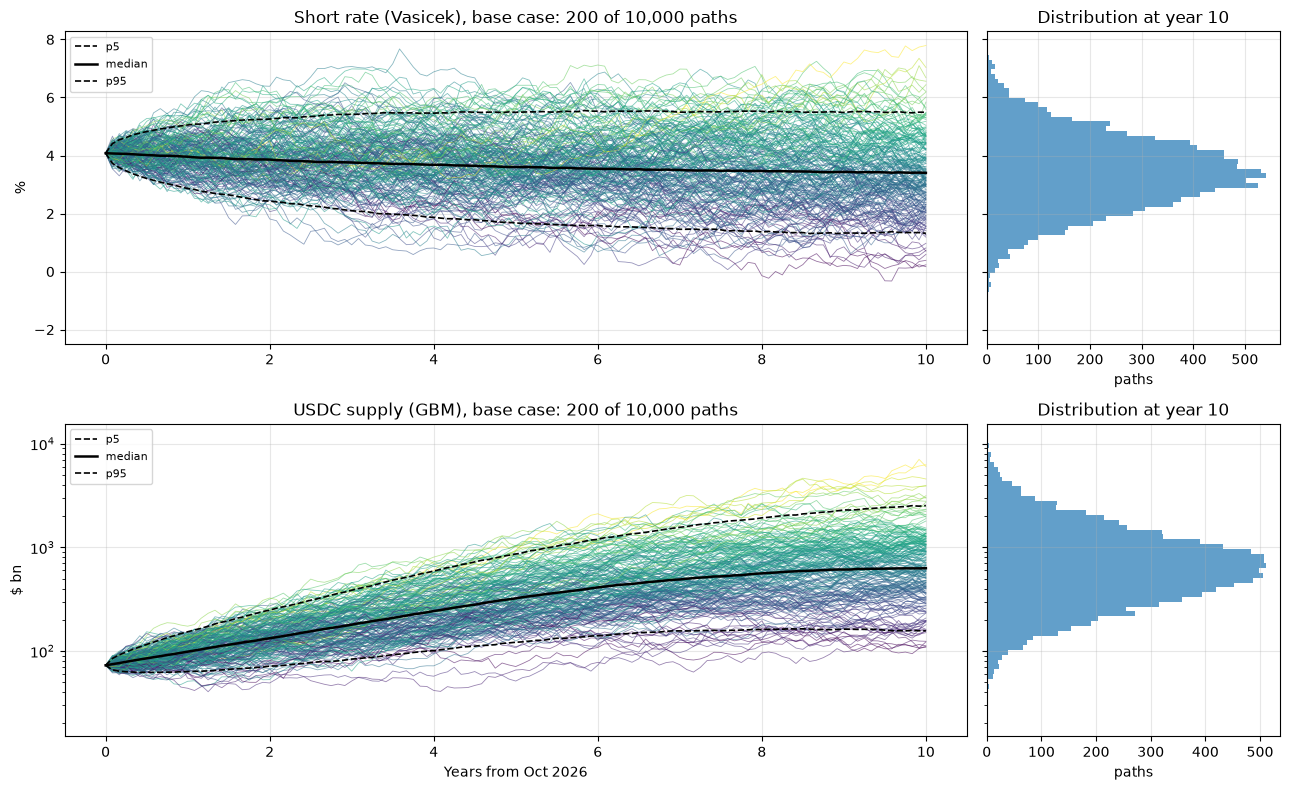

,rate p5 (%),rate median (%),rate p95 (%),rate < 0 (% of paths),USDC p5 ($ bn),USDC median ($ bn),USDC p95 ($ bn)
year 1,2.86,3.96,5.05,0.00,63.26,98.50,153.17
year 5,1.68,3.60,5.49,0.05,121.50,322.06,862.42
year 10,1.32,3.40,5.49,0.39,156.76,629.42,"2,531.81"


In [297]:
N_PATHS = 10_000
STEPS_PER_YEAR = 12
n_steps = calib["HORIZON"] * STEPS_PER_YEAR
dt_sim = 1 / STEPS_PER_YEAR
times = np.arange(n_steps + 1) * dt_sim  # years from END_DATE

def simulate(rate_case="base", usdc_case="base", n_paths=N_PATHS, seed=42):
    """Correlated paths of the short rate (Vasicek, exact step) and USDC supply (GBM with time-varying drift, exact step)."""
    gen = np.random.default_rng(seed)  # fixed seed: same paths every run
    p = calib["rates"][rate_case]
    kappa, theta, sig_r = p["kappa"], p["theta"], p["sigma"]
    sig_s, rho = calib["sigma_usdc"], calib["rho"]

    # Brownian shocks, correlated by Cholesky: z2 = rho * z1 + sqrt(1 - rho^2) * z3
    z1 = gen.standard_normal((n_paths, n_steps))
    z3 = gen.standard_normal((n_paths, n_steps))
    z2 = rho * z1 + np.sqrt(1 - rho**2) * z3

    # Vasicek, exact step: r(t+dt) = theta + (r(t) - theta) * e^(-kappa dt) + sd * z
    e = np.exp(-kappa * dt_sim)
    sd_r = sig_r * np.sqrt((1 - e**2) / (2 * kappa))
    r = np.empty((n_paths, n_steps + 1))
    r[:, 0] = calib["r0"]
    for i in range(n_steps):
        r[:, i + 1] = theta + (r[:, i] - theta) * e + sd_r * z1[:, i]

    # GBM, exact step (Ito): log S rises by (integral of mu over the step) - sigma^2/2 * dt + sigma * sqrt(dt) * z
    m1 = calib["mu1"][usdc_case]
    int_mu = np.diff([np.log(expected_usdc(t, m1) / calib["S0"]) for t in times])
    log_s = np.log(calib["S0"]) + np.cumsum(int_mu - sig_s**2 / 2 * dt_sim + sig_s * np.sqrt(dt_sim) * z2, axis=1)
    S = np.column_stack([np.full(n_paths, calib["S0"]), np.exp(log_s)])
    return r, S

r_sim, S_sim = simulate("base", "base")

idx = [STEPS_PER_YEAR * y for y in (1, 5, 10)]
summary = pd.DataFrame({
    "rate p5 (%)":   np.percentile(r_sim[:, idx], 5, axis=0) * 100,
    "rate median (%)": np.median(r_sim[:, idx], axis=0) * 100,
    "rate p95 (%)":  np.percentile(r_sim[:, idx], 95, axis=0) * 100,
    "rate < 0 (% of paths)": (r_sim[:, idx] < 0).mean(axis=0) * 100,
    "USDC p5 ($ bn)":  np.percentile(S_sim[:, idx], 5, axis=0),
    "USDC median ($ bn)": np.median(S_sim[:, idx], axis=0),
    "USDC p95 ($ bn)": np.percentile(S_sim[:, idx], 95, axis=0),
}, index=["year 1", "year 5", "year 10"])

fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [4, 1.3]}, sharey="row")
cmap = plt.get_cmap("viridis")
n_show = 200  # paths drawn; percentiles use all 10,000
for row, (data, scale, title, unit, log) in enumerate([
        (r_sim, 100, "Short rate (Vasicek), base case", "%", False),
        (S_sim, 1, "USDC supply (GBM), base case", "$ bn", True)]):
    ax, axh = axes[row]
    end = np.log(data[:n_show, -1]) if log else data[:n_show, -1]
    color_pos = (end - end.min()) / (end.max() - end.min())  # colour by where each path ends
    for i in range(n_show):
        ax.plot(times, data[i] * scale, lw=0.6, alpha=0.55, color=cmap(color_pos[i]))
    for q in (5, 50, 95):
        ax.plot(times, np.percentile(data, q, axis=0) * scale, color="black",
                lw=1.8 if q == 50 else 1.2, ls="-" if q == 50 else "--", label="median" if q == 50 else f"p{q}")
    ax.set_title(f"{title}: {n_show} of {N_PATHS:,} paths")
    ax.set_ylabel(unit); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
    final = data[:, -1] * scale
    bins = np.logspace(np.log10(final.min()), np.log10(final.max()), 60) if log else 60
    axh.hist(final, bins=bins, orientation="horizontal", alpha=0.7)
    axh.set_title("Distribution at year 10"); axh.set_xlabel("paths"); axh.grid(alpha=0.3)
    if log:
        ax.set_yscale("log")
axes[1][0].set_xlabel("Years from Oct 2026")
plt.tight_layout()
plt.show()

summary

**Interpretation (simulated paths).** In the base case the median short rate follows the Fed path (3.96%, 3.60% and 3.40% at years 1, 5 and 10), with 90% of paths between 1.3% and 5.5% at year 10; fewer than 0.4% of paths have a negative rate. USDC has a median of $629bn at year 10, with 90% of paths between $157bn and $2.5tn, and in 13% of paths USDC is below today's level after one year. Measured in logs, USDC uncertainty at year 10 is about 1.8 times the rate uncertainty, so USDC growth matters more for the valuation than the rate path. The negative correlation shows in the paths: in the quarter of paths with the lowest rates at year 10 the median USDC is $794bn, against $484bn in the quarter with the highest rates.

### 4.2 Cash flows per path
Each simulated path is turned into an annual P&L and free cash flow to the firm (FCFF), $ mn:
- Reserve income = USDC x simulated rate (reserve return = T-bill, floored at zero; average gap over 2025Q2-2026Q2 was -0.02 pp).
- Distribution and transaction costs = 61.5% of reserve income (2026Q2).
- Other revenue = 0.20% of average USDC (H1 2026 run rate). ARC token presale revenue is excluded: the presale proceeds are recorded as deferred revenue (2026Q2 10-Q), so the cash is already in today's balance sheet.
- Opex = 2026Q2 run rate ($1,018 mn, incl. stock-based compensation and D&A) x (USDC / $76.5bn, the 2026Q2 average)^0.5.
- Tax = 25.63% of positive EBIT (US marginal rate, Damodaran January 2026).
- Capex is set equal to D&A and working-capital changes to zero, so FCFF = EBIT - tax.

In [298]:
# Cash-flow assumptions (sources in comments; $ mn unless noted)
DIST_SHARE = 410.414 / 667.733            # 2026Q2 distribution and transaction costs / reserve income (8-K, Q2 2026)
OTHER_REV_RATIO = (41.625 + 33.582) * 2 / ((75.2 + 76.5) / 2 * 1e3)  # H1 2026 other revenue, annualised / avg USDC
OPEX0 = 254.486 * 4                       # 2026Q2 total operating expenses, annualised (incl. SBC and D&A)
OPEX_USDC0 = 76.5                         # 2026Q2 average USDC, $ bn: the USDC level at which OPEX0 was measured
OPEX_ELASTICITY = 0.5                     # opex grows with USDC^0.5 (3Q24 to 3Q25: 0.46)
TAX_RATE = 0.2563                         # US marginal corporate tax rate (Damodaran, January 2026)

def cash_flows(r, S):
    """Annual P&L and free cash flow to the firm per path, $ mn. Arrays have shape (paths, years)."""
    n = r.shape[0]
    years = (S.shape[1] - 1) // STEPS_PER_YEAR
    # monthly reserve income = USDC x rate x dt, using values at the start of each month; summed by year.
    # The reserve return is floored at zero: reserves (T-bills, repo, cash) do not earn a negative return in practice.
    reserve_income = (S[:, :-1] * np.maximum(r[:, :-1], 0) * dt_sim * 1e3).reshape(n, years, STEPS_PER_YEAR).sum(axis=2)
    avg_usdc = S[:, 1:].reshape(n, years, STEPS_PER_YEAR).mean(axis=2)  # $ bn, average over the year
    distribution = DIST_SHARE * reserve_income
    other_revenue = OTHER_REV_RATIO * avg_usdc * 1e3
    opex = OPEX0 * (avg_usdc / OPEX_USDC0) ** OPEX_ELASTICITY
    ebit = reserve_income - distribution + other_revenue - opex
    tax = TAX_RATE * np.maximum(ebit, 0)  # no tax credit on losses (simplification)
    fcff = ebit - tax                     # capex = D&A and no working-capital change (see 4.2 text)
    return {"reserve_income": reserve_income, "distribution": distribution, "other_revenue": other_revenue,
            "opex": opex, "ebit": ebit, "tax": tax, "fcff": fcff}

cf = cash_flows(r_sim, S_sim)

# Mean of each line for years 1, 5 and 10, plus the 2026Q2 run rate (x4) as a check on year 1
lines = ["reserve_income", "distribution", "other_revenue", "opex", "ebit", "fcff"]
table = pd.DataFrame({f"year {y}": [cf[k][:, y - 1].mean() for k in lines] for y in (1, 5, 10)}, index=lines)
table.insert(0, "2026Q2 x4", [667.733 * 4, 410.414 * 4, 33.582 * 4, OPEX0, np.nan, np.nan])
table.loc["ebit", "2026Q2 x4"] = table.loc[["reserve_income", "other_revenue"], "2026Q2 x4"].sum() - table.loc[["distribution", "opex"], "2026Q2 x4"].sum()
print(f"Paths with negative EBIT: year 1 {(cf['ebit'][:, 0] < 0).mean():.1%}, year 5 {(cf['ebit'][:, 4] < 0).mean():.1%}, year 10 {(cf['ebit'][:, 9] < 0).mean():.1%}")
table

Paths with negative EBIT: year 1 0.1%, year 5 1.8%, year 10 1.8%


,2026Q2 x4,year 1,year 5,year 10
reserve_income,"2,670.93","3,416.37","11,349.68","27,449.44"
distribution,"1,641.66","2,099.83","6,975.94","16,871.47"
other_revenue,134.33,174.32,665.68,"1,725.66"
opex,"1,017.94","1,087.25","2,049.63","3,159.17"
ebit,145.66,403.60,"2,989.79","9,144.46"
fcff,NaN,300.15,"2,222.12","6,797.95"


**Interpretation (cash flows).** Mean EBIT is $404 mn in year 1, against a 2026Q2 run rate of $146 mn, because the base case assumes USDC grows 40% a year from the start while it was flat over the last 12 months. Mean EBIT reaches $2,990 mn in year 5 and $9,144 mn in year 10; mean FCFF is $300 mn, $2,222 mn and $6,798 mn. Partners receive 61.5% of reserve income in every year, more than Circle keeps. Opex grows from $1,087 mn in year 1 to $3,159 mn in year 10, slower than revenue, because of the 0.5 elasticity. EBIT is negative in 1.8% of paths in years 5 and 10: paths where low rates and weak USDC growth coincide.

### 4.3 Discount rate and terminal value
Circle has no debt (its convertible notes converted into equity in 2026Q1), so the discount rate is the cost of equity from the CAPM: 10-year Treasury yield + beta x equity risk premium. CRCL has traded for only 16 months and its regression beta is imprecise, so the beta is shrunk toward the market beta (1.0) with the Vasicek (1973) adjustment, weighting each by its precision.

In [299]:
# CRCL beta: weekly returns since the IPO against the S&P 500
spx = yf.download("^GSPC", start=START_CRCL, auto_adjust=True)["Close"].squeeze().loc[:END_DATE]
prices = pd.concat({"crcl": crcl["Close"], "spx": spx}, axis=1, sort=True).dropna()
weekly = prices.resample("W-FRI").last().pct_change().dropna()

def beta_fit(df):
    fit = stats.linregress(df["spx"], df["crcl"])
    return {"weeks": len(df), "beta": fit.slope, "std_error": fit.stderr, "r_squared": fit.rvalue**2}

pd.DataFrame({
    "since IPO": beta_fit(weekly),
    "excluding IPO months (from Aug 2025)": beta_fit(weekly.loc["2025-08-01":]),
}).T

[*********************100%***********************]  1 of 1 completed


,weeks,beta,std_error,r_squared
since IPO,71.00,1.15,1.15,0.01
excluding IPO months (from Aug 2025),64.00,2.07,0.87,0.08


In [300]:
# Risk-free rate: 10-year Treasury yield at END_DATE (FRED DGS10)
dgs10 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10",
                    index_col=0, parse_dates=True, na_values=".").iloc[:, 0].loc[:END_DATE].dropna()
RF = dgs10.iloc[-1] / 100
ERP = 0.0420  # Damodaran implied equity risk premium, 1 October 2026
G = calib["G_LONG"]  # perpetual growth after year 10

# Vasicek (1973) beta adjustment: shrink the regression beta toward the market beta (1.0),
# weighting each by its precision. Prior dispersion of 0.5 is a standard assumption.
reg = beta_fit(weekly.loc["2025-08-01":])
PRIOR_BETA, PRIOR_SD = 1.0, 0.5
w_reg = PRIOR_SD**2 / (PRIOR_SD**2 + reg["std_error"]**2)
BETA = w_reg * reg["beta"] + (1 - w_reg) * PRIOR_BETA
KE = RF + BETA * ERP  # cost of equity = discount rate (no debt)

def firm_value(fcff, ke=KE, g=G):
    """PV of 10 annual FCFF (mid-year convention) + terminal value at year 10 (Gordon growth), per path, $ mn."""
    years = np.arange(1, fcff.shape[1] + 1)
    pv_flows = (fcff / (1 + ke) ** (years - 0.5)).sum(axis=1)
    terminal = fcff[:, -1] * (1 + g) / (ke - g)
    pv_terminal = terminal / (1 + ke) ** years[-1]
    return pv_flows, pv_terminal

pv_flows, pv_terminal = firm_value(cf["fcff"])
print(f"Risk-free {RF:.2%} (10y Treasury, {dgs10.index[-1]:%d %b %Y}) | regression beta {reg['beta']:.2f} "
      f"(s.e. {reg['std_error']:.2f}) | weight {w_reg:.0%} | beta {BETA:.2f} | cost of equity {KE:.2%} | g {G:.0%}")
pd.DataFrame({
    "mean": [pv_flows.mean(), pv_terminal.mean(), (pv_flows + pv_terminal).mean()],
    "median": [np.median(pv_flows), np.median(pv_terminal), np.median(pv_flows + pv_terminal)],
}, index=["PV of FCFF, years 1-10", "PV of terminal value", "Firm value"])

Risk-free 5.09% (10y Treasury, 16 Oct 2026) | regression beta 2.07 (s.e. 0.87) | weight 25% | beta 1.27 | cost of equity 10.41% | g 4%


,mean,median
"PV of FCFF, years 1-10","15,780.92","12,269.08"
PV of terminal value,"41,008.78","27,089.95"
Firm value,"56,789.69","39,458.87"


**Interpretation (discount rate and firm value).** The regression beta since August 2025 is 2.07 with a standard error of 0.87 and an R-squared of 8%, so it receives a weight of 25%: the adjusted beta is 1.27 and the cost of equity 10.41% (5.09% + 1.27 x 4.20%). Mean firm value is $56.8bn and the median $39.5bn. The terminal value is 72% of the mean, so most of the value depends on the years after 2036. Limitation: the discount rate is fixed while rates are stochastic in the cash flows; the stress case in section 7 also lowers the discount rate.

### 4.4 Value per share
Firm value + corporate cash + investments - debt = equity value, divided by diluted shares. Balance sheet at 30 June 2026 (10-Q). Diluted shares add to the shares outstanding the dilution from options and RSUs measured in 2026Q2 (diluted minus basic weighted shares).

Diluted shares 274.3 mn | price $82.22 (16 Oct 2026) | market cap $22.6 bn | paths below price: 25.7%


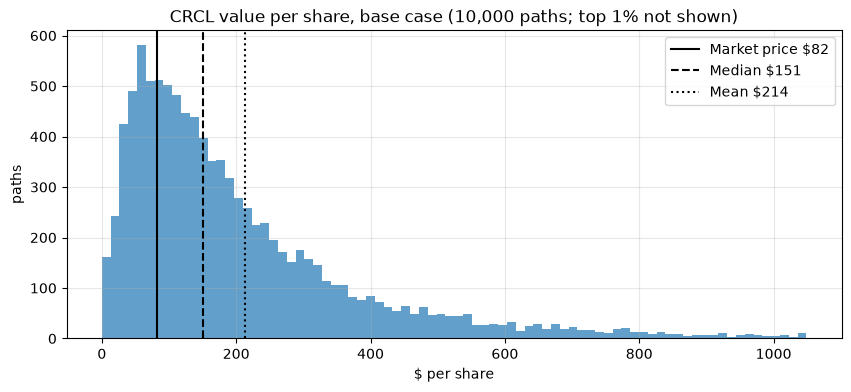

mean     213.79
median   150.52
p5        29.39
p25       80.89
p75      269.57
p95      615.65
Name: value per share ($), base case, dtype: float64

In [301]:
# Bridge from firm value to value per share (balance sheet at 30 Jun 2026, 10-Q; $ mn and mn shares)
CORP_CASH = 1730.126                    # corporate cash and equivalents, not segregated for stablecoin holders
INVESTMENTS = 103.757                   # long-term investments
DEBT = 0.0                              # convertible notes converted into equity in 2026Q1; no borrowings
SHARES_OUT = 234.685190 + 19.190691     # Class A + Class B shares outstanding, 30 Jul 2026 (10-Q cover)
DILUTION = 268.637 - 248.183            # options and RSUs: diluted minus basic weighted shares, 2026Q2
SHARES_DIL = SHARES_OUT + DILUTION
PRICE = crcl["Close"].iloc[-1]          # last close before END_DATE

equity = np.maximum(pv_flows + pv_terminal + CORP_CASH + INVESTMENTS - DEBT, 0)  # shareholders cannot lose more than 0
value_per_share = equity / SHARES_DIL

print(f"Diluted shares {SHARES_DIL:.1f} mn | price ${PRICE:.2f} ({crcl.index[-1]:%d %b %Y}) | "
      f"market cap ${PRICE * SHARES_DIL / 1e3:.1f} bn | paths below price: {(value_per_share < PRICE).mean():.1%}")
result = pd.Series({
    "mean": value_per_share.mean(), "median": np.median(value_per_share),
    "p5": np.percentile(value_per_share, 5), "p25": np.percentile(value_per_share, 25),
    "p75": np.percentile(value_per_share, 75), "p95": np.percentile(value_per_share, 95),
}, name="value per share ($), base case")

fig, ax = plt.subplots(figsize=(10, 4))
upper = np.percentile(value_per_share, 99)  # cut the long right tail for readability
ax.hist(value_per_share[value_per_share <= upper], bins=80, alpha=0.7)
for x, label, style in [(PRICE, f"Market price ${PRICE:.0f}", "-"), (np.median(value_per_share), f"Median ${np.median(value_per_share):.0f}", "--"),
                        (value_per_share.mean(), f"Mean ${value_per_share.mean():.0f}", ":")]:
    ax.axvline(x, color="black", ls=style, lw=1.5, label=label)
ax.set_title(f"CRCL value per share, base case ({N_PATHS:,} paths; top 1% not shown)")
ax.set_xlabel("$ per share"); ax.set_ylabel("paths"); ax.grid(alpha=0.3); ax.legend()
plt.show()

result

**Interpretation (value per share, base case).** Mean value is $214 per share and the median $151, against a market price of $82.22; 26% of paths fall below the price, and 90% lie between $29 and $616. This is conditional on the base case, in which USDC grows 40% a year to 2030 (Circle's own target) while it was flat over the last 12 months. The result therefore says that the market price embeds growth well below Circle's target; section 6 measures how far below. Limitations of the bridge: corporate cash ($1.73bn) includes ARC presale proceeds, which may have to be repaid if product milestones are missed (risk factors, Q2 2026 earnings release); part of the cash may be required as regulatory capital, an amount not disclosed in the documents reviewed; the dilution (20.5 mn shares) is measured in 2026Q2 and changes with the share price.

## 5. Validation against closed form

### 5.1 Simulated moments vs closed-form moments
Both models have exact distributions. Vasicek: r_t is normal with mean theta + (r0 - theta) e^(-kappa t) and variance sigma^2 (1 - e^(-2 kappa t)) / (2 kappa). GBM with time-varying drift (Ito): ln S_t is normal with variance sigma^2 t, and E[S_t] = S0 exp(integral of mu). The simulated means and variances are compared with these values using z = (Monte Carlo - closed form) / Monte Carlo standard error; |z| < 3 means the gap is sampling noise.

In [302]:
# Closed-form moments vs Monte Carlo, base case. Tolerance: |z| < 3, where z = (MC - exact) / MC standard error.
p = calib["rates"]["base"]
kappa, theta, sig_r = p["kappa"], p["theta"], p["sigma"]
sig_s, m1 = calib["sigma_usdc"], calib["mu1"]["base"]
rows = []
for y in (1, 5, 10):
    i = y * STEPS_PER_YEAR
    r_t, s_t = r_sim[:, i], S_sim[:, i]
    # Vasicek: r_t is normal with mean theta + (r0 - theta) e^(-kappa t) and variance sigma^2 / (2 kappa) (1 - e^(-2 kappa t))
    mean_r = theta + (calib["r0"] - theta) * np.exp(-kappa * y)
    var_r = sig_r**2 / (2 * kappa) * (1 - np.exp(-2 * kappa * y))
    # GBM with time-varying drift (Ito): ln S_t is normal with mean ln S0 + integral(mu) - sigma^2 t / 2 and variance sigma^2 t
    mean_s = expected_usdc(y, m1)
    var_ln = sig_s**2 * y
    se_r = r_t.std() / np.sqrt(N_PATHS)
    se_s = s_t.std() / np.sqrt(N_PATHS)
    se_var_ln = var_ln * np.sqrt(2 / (N_PATHS - 1))  # standard error of a normal sample variance
    rows += [
        (f"year {y}", "E[r] (%)",       mean_r * 100, r_t.mean() * 100, (r_t.mean() - mean_r) / se_r),
        (f"year {y}", "Var[r] (x1e4)",  var_r * 1e4, r_t.var() * 1e4, (r_t.var() - var_r) / (var_r * np.sqrt(2 / (N_PATHS - 1)))),
        (f"year {y}", "E[S] ($ bn)",    mean_s, s_t.mean(), (s_t.mean() - mean_s) / se_s),
        (f"year {y}", "Var[ln S]",      var_ln, np.log(s_t).var(), (np.log(s_t).var() - var_ln) / se_var_ln),
    ]
validation = pd.DataFrame(rows, columns=["horizon", "moment", "closed form", "Monte Carlo", "z"]).set_index(["horizon", "moment"])

# Correlation of the simulated shocks: monthly rate changes vs monthly USDC log returns
d_r = np.diff(r_sim, axis=1).ravel()
d_ln_s = np.diff(np.log(S_sim), axis=1).ravel()
rho_mc = np.corrcoef(d_r, d_ln_s)[0, 1]
print(f"Correlation of simulated shocks: {rho_mc:.3f} (target rho = {calib['rho']:.3f})")
print(f"All |z| < 3: {(validation['z'].abs() < 3).all()}")
validation

Correlation of simulated shocks: -0.264 (target rho = -0.266)
All |z| < 3: True


closed form  Monte Carlo     z
horizon moment                                       
year 1  E[r] (%)              3.96         3.96  0.21
        Var[r] (x1e4)         0.45         0.44 -1.52
        E[S] ($ bn)         101.83       102.07  0.85
        Var[ln S]             0.07         0.07  0.34
year 5  E[r] (%)              3.61         3.60 -1.30
        Var[r] (x1e4)         1.35         1.34 -0.78
        E[S] ($ bn)         384.82       385.93  0.44
        Var[ln S]             0.35         0.36  0.68
year 10 E[r] (%)              3.39         3.41  1.07
        Var[r] (x1e4)         1.65         1.60 -2.28
        E[S] ($ bn)         888.48       892.51  0.45
        Var[ln S]             0.71         0.71  0.05

**Interpretation (validation of the simulation).** All simulated means and variances match the closed-form values within three Monte Carlo standard errors (z between -2.28 and +1.07): for example, expected USDC at year 10 is $888.5bn in closed form and $892.5bn in the simulation, and the expected rate is 3.39% and 3.41%. The correlation of the simulated shocks (-0.264) matches the calibrated rho (-0.266). The simulation therefore reproduces the Vasicek and GBM distributions it is built on, and the exact-step scheme introduces no bias.

### 5.2 Convergence, seed stability and deterministic cross-check
Mean value per share and its Monte Carlo standard error for 1,000 to 50,000 paths; the same mean with five other seeds; and a deterministic DCF on the expected rate and USDC paths, with no randomness.

In [303]:
# (a) Convergence: mean value per share and its Monte Carlo standard error for different numbers of paths and seeds
def value_per_share_mc(n_paths, seed, rate_case="base", usdc_case="base"):
    r, S = simulate(rate_case, usdc_case, n_paths=n_paths, seed=seed)
    pv_f, pv_t = firm_value(cash_flows(r, S)["fcff"])
    return np.maximum(pv_f + pv_t + CORP_CASH + INVESTMENTS - DEBT, 0) / SHARES_DIL

conv = []
for n in (1_000, 5_000, 10_000, 50_000):
    v = value_per_share_mc(n, seed=42)
    conv.append({"paths": n, "mean ($)": v.mean(), "std error ($)": v.std() / np.sqrt(n), "median ($)": np.median(v)})
convergence = pd.DataFrame(conv).set_index("paths")
seeds = pd.Series({s: value_per_share_mc(N_PATHS, seed=s).mean() for s in (1, 2, 3, 4, 5)}, name="mean ($), 10,000 paths")

# (b) Deterministic DCF on the expected path (no randomness), as a cross-check of the Monte Carlo mean
r_exp = np.array([[path(p["kappa"], p["theta"] * 100, t) / 100 for t in times]])  # path() works in %
S_exp = np.array([[expected_usdc(t, calib["mu1"]["base"]) for t in times]])
pv_f, pv_t = firm_value(cash_flows(r_exp, S_exp)["fcff"])
det_value = (pv_f + pv_t + CORP_CASH + INVESTMENTS - DEBT)[0] / SHARES_DIL

print(f"Mean value per share across 5 other seeds: {seeds.min():.1f} to {seeds.max():.1f}")
print(f"Deterministic DCF on the expected path: ${det_value:.1f} vs Monte Carlo mean ${value_per_share.mean():.1f} "
      f"and median ${np.median(value_per_share):.1f}")
convergence

Mean value per share across 5 other seeds: 207.4 to 215.9
Deterministic DCF on the expected path: $224.4 vs Monte Carlo mean $213.8 and median $150.5


,mean ($),std error ($),median ($)
paths,,,
1000,221.17,7.49,148.18
5000,213.00,3.10,151.17
10000,213.79,2.14,150.52
50000,211.83,0.99,147.90


**Interpretation (convergence and cross-check).** With 10,000 paths the standard error of the mean value per share is $2.14, so the Monte Carlo mean is precise to about +/-$4 (two standard errors); five other seeds give means between $207.4 and $215.9, inside that range, and 50,000 paths give $211.8. The median is stable at $148-151. A deterministic DCF on the expected rate and USDC paths gives $224.4, about 5% above the Monte Carlo mean. The gap comes from the negative correlation: in paths with more USDC, rates tend to be lower, so average reserve income (USDC x rate) is below the product of the averages. This is the effect that a single-path DCF cannot capture.

### 5.3 Zero-coupon bond prices: Monte Carlo vs Vasicek closed form
The classic test of a short-rate simulation: the price of a zero-coupon bond paying $1 at T is E[exp(-integral of r from 0 to T)], and Vasicek has a closed form P = A(T) exp(-B(T) r0), with B = (1 - e^(-kappa T)) / kappa and ln A = (theta - sigma^2 / (2 kappa^2)) (B - T) - sigma^2 B^2 / (4 kappa). The test uses the base-case parameters: it checks the simulation of the rate path and its integral, not market bond prices.

In [304]:
# Zero-coupon bond price under Vasicek: Monte Carlo E[exp(-integral of r)] vs the closed-form price
def vasicek_bond(T, r0, kappa, theta, sigma):
    """Closed-form zero-coupon bond price: P = A(T) exp(-B(T) r0)."""
    B = (1 - np.exp(-kappa * T)) / kappa
    lnA = (theta - sigma**2 / (2 * kappa**2)) * (B - T) - sigma**2 * B**2 / (4 * kappa)
    return np.exp(lnA - B * r0)

bond_rows = []
for T in (1, 5, 10):
    i = T * STEPS_PER_YEAR
    integral = np.trapezoid(r_sim[:, : i + 1], dx=dt_sim, axis=1)  # integral of r from 0 to T, per path (trapezoid rule)
    disc = np.exp(-integral)
    exact = vasicek_bond(T, calib["r0"], kappa, theta, sig_r)
    bond_rows.append({
        "maturity (years)": T,
        "price closed form ($ per $100)": exact * 100,
        "price Monte Carlo ($ per $100)": disc.mean() * 100,
        "z": (disc.mean() - exact) / (disc.std() / np.sqrt(N_PATHS)),
        "yield closed form (%)": -np.log(exact) / T * 100,
        "yield Monte Carlo (%)": -np.log(disc.mean()) / T * 100,
    })
bonds = pd.DataFrame(bond_rows).set_index("maturity (years)")
print(f"All |z| < 3: {(bonds['z'].abs() < 3).all()}")
bonds

All |z| < 3: True


,price closed form ($ per $100),price Monte Carlo ($ per $100),z,yield closed form (%),yield Monte Carlo (%)
maturity (years),,,,,
1,96.06,96.06,-0.64,4.02,4.02
5,82.67,82.67,0.01,3.81,3.81
10,69.62,69.63,0.31,3.62,3.62


**Interpretation (bond prices).** Monte Carlo bond prices match the Vasicek closed form at all maturities ($96.06, $82.67 and $69.62-69.63 per $100 for 1, 5 and 10 years; z between -0.64 and +0.31), so the simulated rate paths, and not only the rate at each date, follow the model. The model's 10-year yield (3.62%) is well below the market 10-year Treasury yield used as the risk-free rate in 4.3 (5.09%). The gap is expected: the model is calibrated to the expected path of rates (Fed projections), while market yields also include a term premium for holding long bonds. This is why the discount rate uses the market 10-year yield rather than the model.

## 6. Implied interest rate

### 6.1 Implied long-run rate by USDC scenario
For each USDC scenario, find the long-run rate theta at which the mean value per share equals the market price (Brent root finding). The speed of mean reversion, volatility, correlation and discount rate stay as in the base case, and every trial uses the same random draws (seed 42), so the value changes only because theta changes.

In [305]:
def mean_value(theta, m1, n_paths=N_PATHS, seed=42):
    """Mean value per share with long-run rate theta and USDC growth m1 to 2030 (other parameters as in the base case)."""
    calib["rates"]["_trial"] = {**calib["rates"]["base"], "theta": theta}
    calib["mu1"]["_trial"] = m1
    try:
        return value_per_share_mc(n_paths, seed, rate_case="_trial", usdc_case="_trial").mean()
    finally:
        del calib["rates"]["_trial"], calib["mu1"]["_trial"]

THETA_LO, THETA_HI = -0.02, 0.12  # search range for the implied long-run rate

def implied_theta(m1):
    """Long-run rate theta at which the mean value per share equals the market price (Brent root finding)."""
    f = lambda th: mean_value(th, m1) - PRICE
    if f(THETA_LO) > 0:
        return np.nan  # price is below the value even with rates at -2%: no root in range
    if f(THETA_HI) < 0:
        return np.nan  # price is above the value even with rates at 12%
    return optimize.brentq(f, THETA_LO, THETA_HI, xtol=1e-5)

implied = pd.DataFrame({
    "growth to 2030 (% a year)": {k: (np.exp(m) - 1) * 100 for k, m in calib["mu1"].items()},
    "value at Fed theta 3.2% ($)": {k: mean_value(calib["rates"]["base"]["theta"], m) for k, m in calib["mu1"].items()},
    "implied theta (%)": {k: implied_theta(m) * 100 for k, m in calib["mu1"].items()},
}).loc[["bear", "base", "bull"]]
for k in implied.index[implied["implied theta (%)"].isna()]:
    lo, hi = mean_value(THETA_LO, calib["mu1"][k]), mean_value(THETA_HI, calib["mu1"][k])
    print(f"{k}: no implied theta between {THETA_LO:.0%} and {THETA_HI:.0%}: value ranges from ${lo:.1f} to ${hi:.1f}, "
          f"and the price ${PRICE:.2f} is outside that range")
implied

bear: no implied theta between -2% and 12%: value ranges from $0.1 to $65.1, and the price $82.22 is outside that range


,growth to 2030 (% a year),value at Fed theta 3.2% ($),implied theta (%)
bear,0.00,12.75,NaN
base,40.00,213.79,0.63
bull,56.00,484.17,-0.93


**Interpretation (implied rate by scenario).** No scenario explains the market price with normal rates. In the base case (USDC growth of 40% a year to 2030, Circle's target), the price of $82.22 requires a long-run rate of 0.63%, close to the zero-rate regime of 2009-2015. In the bull case it requires a negative long-run rate (-0.93%). In the bear case (no USDC growth) no rate between -2% and 12% is enough: even at 12% the value is $65. The price therefore sits between the bear and base cases: it embeds either much lower rates than the Fed projects, or USDC growth well below Circle's target, or a mix of both.

### 6.2 Implied rate as a function of USDC growth
The implied long-run rate for USDC growth between 15% and 56% a year to 2030, and the reverse question: the USDC growth the price implies at the Fed's long-run rate (3.2%) and at the stress rate (1.44%).

USDC growth to 2030 implied by the price: 24.0% a year at the Fed long-run rate (3.2%); 33.8% a year at the stress rate (1.44%)
Implied USDC in 2030 at the Fed rate: $179bn (9% of a $2tn stablecoin market)


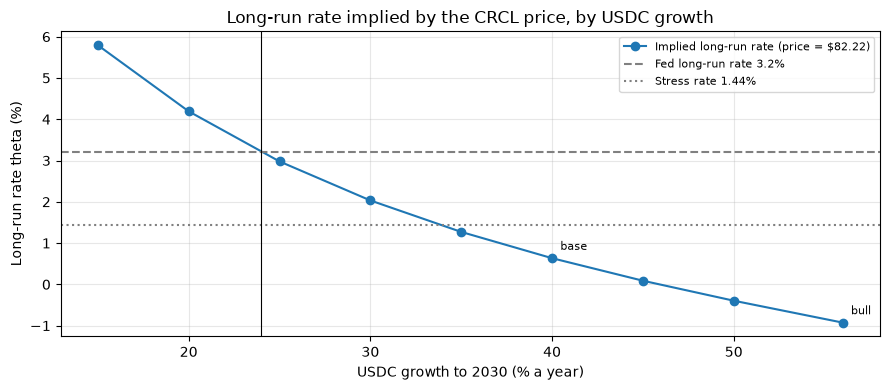

,implied theta (%)
0.15,5.79
0.20,4.19
0.25,2.98
0.30,2.03
0.35,1.27
0.40,0.63
0.45,0.09
0.50,-0.40
0.56,-0.93


In [306]:
# Implied long-run rate as a function of USDC growth to 2030, and the growth implied at the Fed's long-run rate
growth_grid = np.array([0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.56])  # annual growth to 2030
curve = pd.Series({g: implied_theta(np.log(1 + g)) * 100 for g in growth_grid}, name="implied theta (%)")

theta_fed, theta_stress = calib["rates"]["base"]["theta"], calib["rates"]["stress"]["theta"]
mu_at_fed = optimize.brentq(lambda m: mean_value(theta_fed, m) - PRICE, 0.0, calib["mu1"]["bull"], xtol=1e-5)
mu_at_stress = optimize.brentq(lambda m: mean_value(theta_stress, m) - PRICE, 0.0, calib["mu1"]["bull"], xtol=1e-5)
print(f"USDC growth to 2030 implied by the price: {np.exp(mu_at_fed) - 1:.1%} a year at the Fed long-run rate "
      f"({theta_fed:.1%}); {np.exp(mu_at_stress) - 1:.1%} a year at the stress rate ({theta_stress:.2%})")
print(f"Implied USDC in 2030 at the Fed rate: ${expected_usdc(calib['T1'], mu_at_fed):.0f}bn "
      f"({expected_usdc(calib['T1'], mu_at_fed) / STABLE_2030:.0%} of a $2tn stablecoin market)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve.index * 100, curve.values, marker="o", label="Implied long-run rate (price = $%.2f)" % PRICE)
ax.axhline(theta_fed * 100, color="gray", ls="--", label=f"Fed long-run rate {theta_fed:.1%}")
ax.axhline(theta_stress * 100, color="gray", ls=":", label=f"Stress rate {theta_stress:.2%}")
ax.axvline((np.exp(mu_at_fed) - 1) * 100, color="black", lw=0.8)
for k in ("base", "bull"):
    g = (np.exp(calib["mu1"][k]) - 1) * 100
    ax.annotate(k, (g, implied.loc[k, "implied theta (%)"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("USDC growth to 2030 (% a year)"); ax.set_ylabel("Long-run rate theta (%)")
ax.set_title("Long-run rate implied by the CRCL price, by USDC growth")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

curve.to_frame()

**Interpretation (implied rate and implied growth).** The implied long-run rate falls as assumed USDC growth rises: from 5.8% at 15% growth a year to 0.6% at 40% (Circle's target) and below zero above 45%. At the Fed's long-run rate (3.2%), the market price of $82.22 implies USDC growth of 24.0% a year to 2030, about 60% of Circle's 40% target, which would take USDC to about $179bn in 2030 (9% of Standard Chartered's $2tn stablecoin market, against 23.5% today). At the stress rate (1.44%), the price implies 33.8% a year. The market therefore prices substantial growth, but well below management's target, and expects USDC to lose share of the stablecoin market. Limitation: the implied values are conditional on the other base-case assumptions (partner share, opex elasticity, discount rate), which are tested in section 7.

### 6.3 Value map: long-run rate x USDC growth
Mean value per share for each combination of long-run rate (0% to 6%) and USDC growth to 2030 (0% to 56% a year), other assumptions as in the base case. Colours are centred on the market price: red cells are below it, blue cells above it, and the black line marks where value equals the price (interpolated between grid points).

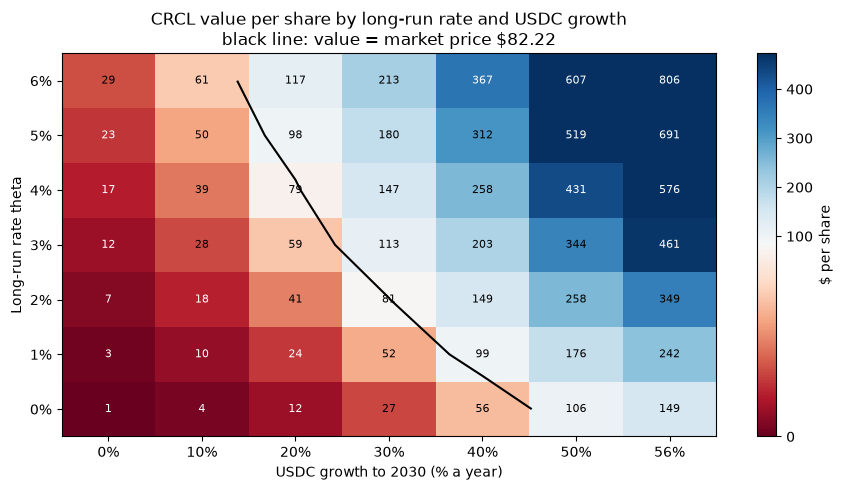

USDC growth to 2030 (a year),0%,10%,20%,30%,40%,50%,56%
long-run rate theta,,,,,,,
0%,1.10,4.20,11.80,27.50,56.40,105.50,148.50
1%,3.10,9.70,24.20,51.60,98.90,176.10,241.80
2%,6.70,18.00,40.60,81.20,149.20,257.60,348.80
3%,11.60,28.10,59.20,113.50,202.90,343.60,461.40
4%,17.40,38.90,78.50,146.60,257.50,431.10,575.90
5%,23.40,49.90,98.00,179.80,312.40,518.90,690.70
6%,29.40,60.90,117.40,213.00,367.30,606.70,805.60


In [307]:
# Value per share (Monte Carlo mean) for each combination of long-run rate and USDC growth to 2030
from matplotlib.colors import TwoSlopeNorm

theta_grid = np.array([0.00, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06])
growth_cols = np.array([0.00, 0.10, 0.20, 0.30, 0.40, 0.50, 0.56])
grid = pd.DataFrame([[mean_value(th, np.log(1 + g)) for g in growth_cols] for th in theta_grid],
                    index=[f"{th:.0%}" for th in theta_grid], columns=[f"{g:.0%}" for g in growth_cols])
grid.index.name, grid.columns.name = "long-run rate theta", "USDC growth to 2030 (a year)"

fig, ax = plt.subplots(figsize=(9, 5))
# Diverging colours centred on the market price: red below the price, blue above, white at the price
norm = TwoSlopeNorm(vmin=0, vcenter=PRICE, vmax=np.percentile(grid.values, 90))
im = ax.imshow(grid.values, cmap="RdBu", norm=norm, origin="lower", aspect="auto")
for i in range(len(theta_grid)):
    for j in range(len(growth_cols)):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if abs(norm(v) - 0.5) > 0.35 else "black")
ax.contour(grid.values, levels=[PRICE], colors="black", linewidths=1.5)  # line where value = market price
ax.set_xticks(range(len(growth_cols)), grid.columns); ax.set_yticks(range(len(theta_grid)), grid.index)
ax.set_xlabel("USDC growth to 2030 (% a year)"); ax.set_ylabel("Long-run rate theta")
ax.set_title(f"CRCL value per share by long-run rate and USDC growth\nblack line: value = market price \\${PRICE:.2f}")  # \\$ avoids math text
fig.colorbar(im, ax=ax, label="\\$ per share")
plt.tight_layout()
plt.show()

grid.round(1)

**Interpretation (value map).** USDC growth drives the value far more than the long-run rate. At a 3% long-run rate, raising growth to 2030 from 30% to 40% a year lifts the value from $113 to $203 per share (+79%), while raising the rate from 3% to 4% at 30% growth lifts it from $113 to $147 (+29%). The market price of $82.22 is matched along the black line: for example 2% rates with about 30% growth, 3% with about 25%, or 6% with about 15%. With no USDC growth, the value stays below $30 per share at any rate up to 6%; at Circle's 40% target, it exceeds the price at any rate above about 0.6%.

### 6.4 Implied return by USDC scenario
The discount rate at which the mean value per share equals the market price: the annual return an investor buying at $82.22 would earn if the scenario's cash flows materialise (Fed rates, same random draws), compared with the 10.41% cost of equity.

In [308]:
# Implied return: the discount rate at which the mean value per share equals the market price, by USDC scenario
def value_at_ke(fcff, ke):
    pv_f, pv_t = firm_value(fcff, ke=ke)
    return (np.maximum(pv_f + pv_t + CORP_CASH + INVESTMENTS - DEBT, 0) / SHARES_DIL).mean()

KE_LO, KE_HI = G + 0.005, 0.60  # the discount rate must stay above perpetual growth (4%)
rows = {}
for k in ("bear", "base", "bull"):
    fcff_k = cash_flows(*simulate("base", k))["fcff"]  # Fed rates, scenario growth, same random draws
    f = lambda ke: value_at_ke(fcff_k, ke) - PRICE
    irr = optimize.brentq(f, KE_LO, KE_HI, xtol=1e-6) if f(KE_LO) > 0 > f(KE_HI) else np.nan
    rows[k] = {"value at cost of equity 10.41% ($)": value_at_ke(fcff_k, KE),
               "implied return (% a year)": irr * 100,
               "excess over cost of equity (pp)": (irr - KE) * 100}
implied_return = pd.DataFrame(rows).T
for k in implied_return.index[implied_return["implied return (% a year)"].isna()]:
    print(f"{k}: value stays below the price for any discount rate above {KE_LO:.1%}: no implied return in range")
implied_return

,value at cost of equity 10.41% ($),implied return (% a year),excess over cost of equity (pp)
bear,12.75,4.71,-5.70
base,213.79,17.65,7.24
bull,484.17,26.50,16.10


**Interpretation (implied return).** An investor buying at $82.22 earns about 17.7% a year if the base case materialises (USDC growth of 40% a year to 2030 and Fed rates), 7.2 pp above the 10.41% cost of equity, and 26.5% in the bull case. In the bear case (no USDC growth) the return falls to about 4.7% a year, below the 5.09% risk-free rate. The share is therefore an asymmetric bet on USDC growth: well rewarded if growth resumes, worse than Treasuries if it does not. The bear figure should be read with care: at discount rates this close to the 4% perpetual growth rate, the terminal value is very sensitive to small changes.

### 6.5 Implied growth in context
The USDC growth implied by the price (6.2) next to the growth observed in different windows (3.3) and the published targets (3.4). All figures are expected annual growth, e^mu - 1, so they are directly comparable.

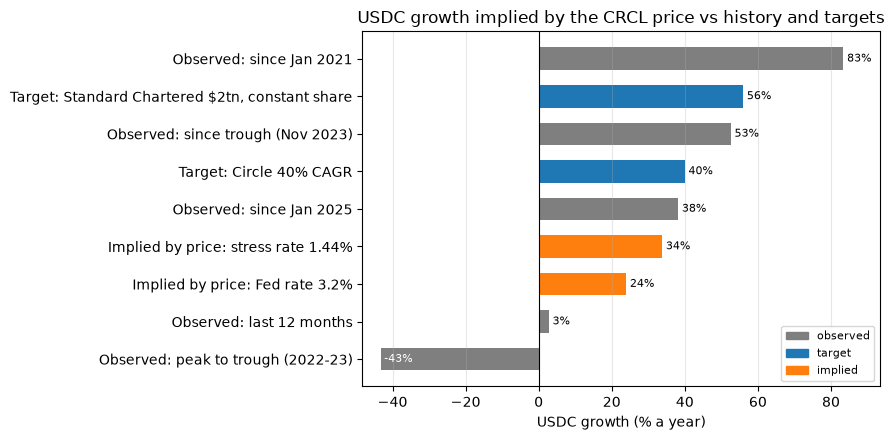

,type,annual growth (%)
reference,,
Observed: peak to trough (2022-23),observed,-43.27
Observed: last 12 months,observed,2.80
Implied by price: Fed rate 3.2%,implied,23.98
Implied by price: stress rate 1.44%,implied,33.82
Observed: since Jan 2025,observed,38.20
Target: Circle 40% CAGR,target,40.00
Observed: since trough (Nov 2023),observed,52.61
"Target: Standard Chartered $2tn, constant share",target,56.00
Observed: since Jan 2021,observed,83.41


In [309]:
# Price-implied USDC growth next to observed history and published targets (all as annual growth = e^mu - 1)
refs = [
    ("Observed: since Jan 2021",                 "observed", fit_gbm(logret.loc["2021-01":])["mu_pct"] / 100),
    ("Observed: peak to trough (2022-23)",       "observed", fit_gbm(logret.loc["2022-07":"2023-11"])["mu_pct"] / 100),
    ("Observed: since trough (Nov 2023)",        "observed", fit_gbm(logret.loc["2023-12":])["mu_pct"] / 100),
    ("Observed: since Jan 2025",                 "observed", fit_gbm(logret.loc["2025-01":])["mu_pct"] / 100),
    ("Observed: last 12 months",                 "observed", fit_gbm(logret.loc["2025-10":])["mu_pct"] / 100),
    ("Target: Circle 40% CAGR",                  "target",   calib["mu1"]["base"]),
    ("Target: Standard Chartered $2tn, constant share", "target", calib["mu1"]["bull"]),
    ("Implied by price: Fed rate 3.2%",          "implied",  mu_at_fed),
    ("Implied by price: stress rate 1.44%",      "implied",  mu_at_stress),
]
context = pd.DataFrame(refs, columns=["reference", "type", "mu"]).set_index("reference")
context["annual growth (%)"] = (np.exp(context["mu"]) - 1) * 100
context = context.drop(columns="mu").sort_values("annual growth (%)")

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {"observed": "tab:gray", "target": "tab:blue", "implied": "tab:orange"}
ax.barh(context.index, context["annual growth (%)"], color=[colors[t] for t in context["type"]], height=0.6)
for y, v in enumerate(context["annual growth (%)"]):  # labels outside positive bars, inside negative ones
    ax.text(v + 1, y, f"{v:.0f}%", va="center", ha="left", fontsize=8,
            color="black" if v >= 0 else "white")
ax.set_xlim(context["annual growth (%)"].min() - 5, context["annual growth (%)"].max() + 10)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("USDC growth (% a year)")
ax.set_title("USDC growth implied by the CRCL price vs history and targets")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

context

**Interpretation (implied growth in context).** The growth the market prices in at Fed rates (24% a year to 2030) sits between the stagnation of the last 12 months (2.8%) and Circle's 40% target, and well below the pace observed since the November 2023 trough (52.6%) or since January 2025 (38.2%). Even at the stress rate, the implied growth (33.8%) stays below the target. The market therefore neither extrapolates the recent stall nor accepts management's target: it prices a partial recovery of USDC growth. The 2021 figure (83%) reflects growth from a small base ($3.7bn) and is shown only for completeness.

## 7. Sensitivity and rate-cut scenario

### 7.1 Scenario table
Value per share for each combination of rate scenario (base: Fed long-run rate 3.2%; stress: historical fit, 1.44%) and USDC scenario (bear, base, bull). Every cell uses the same random draws, so differences come only from the assumptions.

In [310]:
# Value per share for each combination of rate scenario and USDC scenario (same random draws in every cell)
scen_rows = []
for rate_case in ("base", "stress"):
    for usdc_case in ("bear", "base", "bull"):
        v = value_per_share_mc(N_PATHS, seed=42, rate_case=rate_case, usdc_case=usdc_case)
        scen_rows.append({
            "rates": f"{rate_case} (theta {calib['rates'][rate_case]['theta']:.2%})",
            "USDC": f"{usdc_case} ({np.exp(calib['mu1'][usdc_case]) - 1:.0%} a year to 2030)",
            "mean ($)": v.mean(), "median ($)": np.median(v),
            "p5 ($)": np.percentile(v, 5), "p95 ($)": np.percentile(v, 95),
            "paths below price (%)": (v < PRICE).mean() * 100,
        })
scenario_table = pd.DataFrame(scen_rows).set_index(["rates", "USDC"])
print(f"Market price ${PRICE:.2f}")
scenario_table

Market price $82.22


mean ($)  median ($)  p5 ($)  \
rates                USDC                                                      
base (theta 3.20%)   bear (0% a year to 2030)      12.75        7.72    0.00   
                     base (40% a year to 2030)    213.79      150.52   29.39   
                     bull (56% a year to 2030)    484.17      346.89   78.77   
stress (theta 1.44%) bear (0% a year to 2030)       6.16        0.61    0.00   
                     base (40% a year to 2030)    137.70       90.81    0.00   
                     bull (56% a year to 2030)    323.54      220.84   16.31   

                                                p95 ($)  paths below price (%)  
rates                USDC                                                       
base (theta 3.20%)   bear (0% a year to 2030)     44.36                  99.11  
                     base (40% a year to 2030)   615.65                  25.72  
                     bull (56% a year to 2030) 1,371.83                   5.56  
stress (theta 1.44%) bear (0% a year to 2030)     27.47                  99.78  
                     base (40% a year to 2030)   432.01                  46.30  
                     bull (56% a year to 2030)   973.79                  19.17

**Interpretation (scenario table).** USDC growth dominates the result: with Fed rates, the mean value goes from $13 per share (bear) to $214 (base) and $484 (bull). The stress rate path cuts about a third of the value in the base and bull cases ($214 to $138 and $484 to $324). Against the market price of $82.22, the bear case is below the price in almost every path (99%), the base case in 26% of paths with Fed rates and 46% with stress rates, and the bull case in 6% to 19%. The share therefore looks undervalued only if USDC growth resumes; if it stays flat, no rate scenario supports the current price. The p5 of zero in some cells reflects paths with negative firm value, floored at zero for shareholders.

### 7.2 One-at-a-time sensitivity (tornado)
Each assumption is moved to an unfavourable and a favourable value while all others stay at the base case (base-case paths, Fed rates, 40% USDC growth to 2030). Ranges: opex elasticity 1.0 (no scale economies) to 0.25; cost of equity +/-1 pp; perpetual growth 3% to 5%; partner share 64% (2025Q2) to 60%; reserve return 0.13 pp below the T-bill (2026Q1-Q2) to 0.10 pp above (2025Q3-Q4); tax rate 21% (federal only) instead of 25.63%.

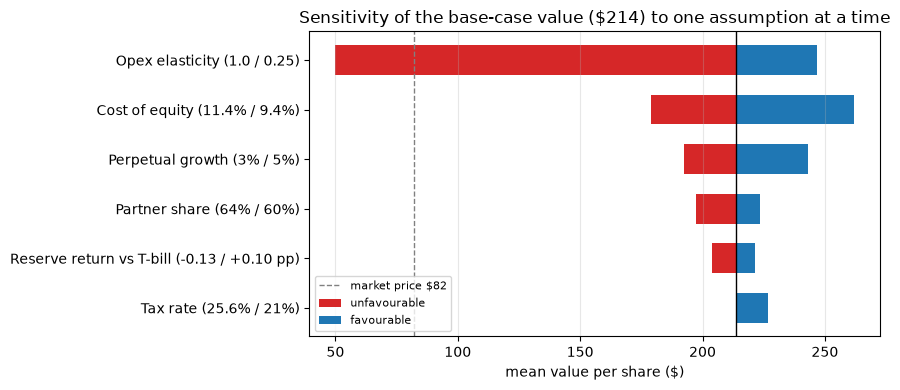

Base-case mean value per share: $213.79


,low ($),high ($),range ($)
Opex elasticity (1.0 / 0.25),49.91,246.90,196.99
Cost of equity (11.4% / 9.4%),179.14,261.92,82.79
Perpetual growth (3% / 5%),192.34,243.18,50.83
Partner share (64% / 60%),197.20,223.37,26.17
Reserve return vs T-bill (-0.13 / +0.10 pp),203.72,221.55,17.83
Tax rate (25.6% / 21%),213.79,226.70,12.91


In [311]:
# One-at-a-time sensitivity of the mean value per share (base case paths; every other assumption at its base value)
def value_with(dist=None, elasticity=None, tax=None, ke=KE, g=G, spread=0.0, r=r_sim, S=S_sim):
    """Mean value per share with some assumptions changed. spread is subtracted from the reserve return."""
    global DIST_SHARE, OPEX_ELASTICITY, TAX_RATE
    saved = (DIST_SHARE, OPEX_ELASTICITY, TAX_RATE)
    DIST_SHARE = saved[0] if dist is None else dist
    OPEX_ELASTICITY = saved[1] if elasticity is None else elasticity
    TAX_RATE = saved[2] if tax is None else tax
    try:
        fcff = cash_flows(r - spread, S)["fcff"]
    finally:
        DIST_SHARE, OPEX_ELASTICITY, TAX_RATE = saved
    pv_f, pv_t = firm_value(fcff, ke=ke, g=g)
    return (np.maximum(pv_f + pv_t + CORP_CASH + INVESTMENTS - DEBT, 0) / SHARES_DIL).mean()

base_value = value_with()
tests = {  # assumption (unfavourable / favourable value): (unfavourable setting, favourable setting)
    "Opex elasticity (1.0 / 0.25)":                (dict(elasticity=1.0), dict(elasticity=0.25)),
    "Cost of equity (11.4% / 9.4%)":               (dict(ke=KE + 0.01), dict(ke=KE - 0.01)),
    "Perpetual growth (3% / 5%)":                  (dict(g=G - 0.01), dict(g=G + 0.01)),
    "Partner share (64% / 60%)":                   (dict(dist=0.64), dict(dist=0.60)),
    "Reserve return vs T-bill (-0.13 / +0.10 pp)": (dict(spread=0.0013), dict(spread=-0.0010)),
    "Tax rate (25.6% / 21%)":                      (dict(), dict(tax=0.21)),
}
tornado = pd.DataFrame({k: {"low ($)": value_with(**lo), "high ($)": value_with(**hi)} for k, (lo, hi) in tests.items()}).T
tornado["range ($)"] = tornado["high ($)"] - tornado["low ($)"]
tornado = tornado.sort_values("range ($)")

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(tornado))
ax.barh(y, tornado["low ($)"] - base_value, left=base_value, color="tab:red", height=0.6, label="unfavourable")
ax.barh(y, tornado["high ($)"] - base_value, left=base_value, color="tab:blue", height=0.6, label="favourable")
ax.axvline(base_value, color="black", lw=1)
ax.axvline(PRICE, color="gray", ls="--", lw=1, label=f"market price \\${PRICE:.0f}")
ax.set_yticks(y, tornado.index)
ax.set_xlabel("mean value per share (\\$)")
ax.set_title(f"Sensitivity of the base-case value (\\${base_value:.0f}) to one assumption at a time")
ax.grid(axis="x", alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

print(f"Base-case mean value per share: ${base_value:.2f}")
tornado.sort_values("range ($)", ascending=False)

**Interpretation (sensitivity).** The opex elasticity is by far the most important assumption. If costs grow in proportion to USDC (elasticity 1.0, no scale economies), the base-case value falls from $214 to $50 per share, below the $82.22 price, even with USDC growing 40% a year to 2030; with an elasticity of 0.25 it rises to $247. Over the last year Circle's costs grew faster than USDC (year-on-year elasticities of 1.26 and 1.51 in 2026Q1 and 2026Q2, against 0.46 from 2024Q3 to 2025Q3), so scale economies are not yet visible in the data. The cost of equity (+/-1 pp: $179 to $262) and the perpetual growth rate (3% to 5%: $192 to $243) come next. The partner share, the reserve-return gap and the tax rate move the value by less than $27 each. The value therefore depends on two things above all: USDC growth and whether Circle gains scale on its costs.

### 7.3 Rate-cut scenario
Four versions of a rate cut, all with base-case USDC growth: (1) the base case; (2) an immediate 1 pp cut in today's rate, with the long-run rate unchanged, so the cut fades at the base speed of mean reversion; (3) a persistent cut, with the long-run rate falling to the stress level (1.44%) while the discount rate stays at 10.41%; (4) the same persistent cut, with the risk-free rate in the discount rate falling by the same amount (1.76 pp).

In [312]:
# Rate-cut scenarios, base-case USDC growth (40% a year to 2030), same random draws
def value_rate_case(rate_case="base", r0_shift=0.0, ke=KE):
    """Mean and median value per share with a rate scenario, an optional shift of today's rate, and a given discount rate."""
    r0_saved = calib["r0"]
    calib["r0"] = r0_saved + r0_shift
    try:
        r, S = simulate(rate_case, "base")
    finally:
        calib["r0"] = r0_saved
    pv_f, pv_t = firm_value(cash_flows(r, S)["fcff"], ke=ke)
    v = np.maximum(pv_f + pv_t + CORP_CASH + INVESTMENTS - DEBT, 0) / SHARES_DIL
    return {"mean ($)": v.mean(), "median ($)": np.median(v), "paths below price (%)": (v < PRICE).mean() * 100}

cut = calib["rates"]["base"]["theta"] - calib["rates"]["stress"]["theta"]  # long-run cut, about 1.76 pp
rate_cut = pd.DataFrame({
    "1. Base: Fed path, cost of equity 10.41%":                value_rate_case(),
    "2. Immediate 1 pp cut, long-run rate unchanged":          value_rate_case(r0_shift=-0.01),
    f"3. Persistent cut to {calib['rates']['stress']['theta']:.2%}, discount rate unchanged": value_rate_case("stress"),
    f"4. Persistent cut, discount rate also {cut * 100:.2f} pp lower ({KE - cut:.2%})": value_rate_case("stress", ke=KE - cut),
}).T
rate_cut["change vs base (%)"] = (rate_cut["mean ($)"] / rate_cut["mean ($)"].iloc[0] - 1) * 100
rate_cut

,mean ($),median ($),paths below price (%),change vs base (%)
"1. Base: Fed path, cost of equity 10.41%",213.79,150.52,25.72,0.00
"2. Immediate 1 pp cut, long-run rate unchanged",190.83,132.51,31.27,-10.74
"3. Persistent cut to 1.44%, discount rate unchanged",137.70,90.81,46.30,-35.59
"4. Persistent cut, discount rate also 1.76 pp lower (8.64%)",199.39,127.32,36.57,-6.74


**Interpretation (rate-cut scenario).** An immediate 1 pp cut in today's rate, fading back to the Fed path, lowers the mean value by 11% ($214 to $191). A persistent cut of the long-run rate to 1.44% lowers it by 36% ($138) if the discount rate stays at 10.41%, but only by 7% ($199) if the risk-free rate in the discount rate falls by the same 1.76 pp: lower reserve income is largely offset by a lower discount rate. Circle's rate exposure is therefore smaller than its revenue sensitivity suggests, provided long-term yields fall together with short-term rates. If long-term yields do not fall with short-term rates, the third case is the relevant one; at the valuation date the 10-year yield (5.09%) is already about 1 pp above the 3-month T-bill (4.08%).

## 8. Conclusions and limitations